In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from datetime import datetime
import numpy as np
import random


class Network:
    def __init__(self, environment, network_type="random",
                 p=0.2, # random and Watts-Strogatz 
                 number_of_clusters=2, p_inside=0.7, p_outside=0.1, # Clustered
                 mean_degree = 4, # Watts-Strogatz
                 edges = 1, # Barabasi-Albert
                 seed=None):

        self.agents = environment.agents
        self.N = environment.N
        self.Lambda = environment.Lambda

        self.network_type = network_type

        if seed is not None:
            random.seed(seed)
            np.random.seed(seed)

        if (network_type == "grid") and (int(np.sqrt(self.N))**2 != self.N):
            self.network_type = 'random'
            print('Grid type must be an squared number of individuals')

        if self.network_type == "grid":
            self.G = self._grid_network()

        elif self.network_type == "clustered":
            self.number_of_clusters = number_of_clusters
            self.p_inside = p_inside
            self.p_outside = p_outside
            self.G = self._clustered_network()

        elif (self.network_type == 'Watts-Strogatz') or (self.network_type == 'WS'):
            self.network_type = 'Watts-Strogatz'
            self.p = p
            self.mean_degree_par = mean_degree
            self.G = nx.watts_strogatz_graph(self.N, mean_degree, p, seed=seed)

        elif (self.network_type == 'Barabasi-Albert') or (self.network_type == 'BA'):
            self.network_type = 'Barabasi-Albert'
            self.p = p
            self.edges_par = edges
            self.G = nx.barabasi_albert_graph(self.N, edges, seed=seed)
            

        else: # elif: network_type == "random":
            self.network_type = 'random'
            self.p = p
            self.G = nx.gnp_random_graph(self.N, p, seed=seed)

        # Ambos almacenan la misma información
        self.agents_by_node = {}
        for node, agent in zip(self.G.nodes(), self.agents):
            self.agents_by_node[node] = agent

        for node, agent in self.agents_by_node.items():
            agent.neighbors = [self.agents_by_node[neighbor_node] for neighbor_node in self.G.neighbors(node)]

        self.agent_to_node = {agent: node for node, agent in self.agents_by_node.items()}
        
    def _grid_network(self):       
        G = nx.grid_2d_graph(int(np.sqrt(self.N)), int(np.sqrt(self.N)))
    
        # Add diagonal neighbourhood connections
        for x in range(int(np.sqrt(self.N)) - 1):
            for y in range(int(np.sqrt(self.N)) - 1):
                G.add_edge((x, y),(x + 1, y + 1))
                G.add_edge((x, y + 1),(x + 1, y))
    
        return G

    def _clustered_network(self):
        # 1. División equilibrada de tamaños de clusters
        base_size = self.N // self.number_of_clusters
        sizes = [base_size] * self.number_of_clusters
        sizes[-1] += self.N - sum(sizes)  # Ajuste para el remanente de N
    
        # 2. Construcción de la matriz de probabilidades de enlace (SBM)
        # P_ij = p_inside si i == j, de lo contrario p_outside
        probs = [
            [self.p_inside if i == j else self.p_outside 
             for j in range(self.number_of_clusters)]
            for i in range(self.number_of_clusters)
        ]
    
        # 3. Generación estocástica garantizando que no existan nodos aislados
        while True:
            G = nx.stochastic_block_model(sizes, probs, seed=random.randint(0, 1000000))
            
            # Verificar que el grafo sea completamente conectado o no tenga nodos de grado 0
            if all(deg >= 1 for _, deg in G.degree()):
                break
    
        # 4. Asignar atributo de cluster a los nodos (útil para métricas y visualización)
        start_idx = 0
        for cluster_id, size in enumerate(sizes):
            for node in range(start_idx, start_idx + size):
                G.nodes[node]['cluster'] = cluster_id
            start_idx += size
    
        return G

    def graph(self, save = False):
        COLOR_PATIENT = "#4A90E2"
        COLOR_IMPATIENT = "#D9534F"
        COLOR_EDGE = "#BDC3C7"
    
        patient_nodes = []
        impatient_nodes = []
    
        for node in self.G.nodes():
            agent = self.agents_by_node[node]
    
            if agent.is_patient:
                patient_nodes.append(node)
            else:
                impatient_nodes.append(node)
    

        if self.network_type == "grid":
            self.pos = {node: node for node in self.G.nodes()}
        elif self.network_type == "clustered":
            self.pos = nx.spring_layout(self.G, k=0.15, iterations=100, seed=42)
        else:
            self.pos = nx.spring_layout(self.G, seed=42)

        fig, ax = plt.subplots(figsize=(10, 7), dpi=300)
        
        nx.draw_networkx_edges(self.G, self.pos, ax=ax, edge_color=COLOR_EDGE, style="dashed", width=1.5, alpha=0.8)
        nx.draw_networkx_nodes(self.G, self.pos, ax=ax, nodelist=patient_nodes, node_color=COLOR_PATIENT, edgecolors="#2C3E50", node_size=380, linewidths=1.2)
        nx.draw_networkx_nodes(self.G, self.pos, ax=ax, nodelist=impatient_nodes, node_color=COLOR_IMPATIENT, edgecolors="#5B1208", node_size=380, linewidths=1.2)

        if self.network_type == "grid":
            labels = {node: i for i, node in enumerate(self.G.nodes())}
            nx.draw_networkx_labels(self.G, self.pos, ax=ax, labels=labels, font_size=11, font_color="white", font_weight="bold")
        else:
            nx.draw_networkx_labels(self.G, self.pos, ax=ax, font_size=11, font_color="white", font_weight="bold")

        
        ax.set_title("Depositor Interaction Network Topology", loc="left", fontweight="bold", pad=20, fontsize=18)
        if self.network_type == 'clustered':
            ax.text(0, 1, rf"Model Parameters: $N = {self.N}$, $\lambda = {self.Lambda}$, {self.network_type.capitalize()} Network ($C = $ {self.number_of_clusters}, $p_i =$ {self.p_inside}, $p_o =$ {self.p_outside})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
        elif self.network_type == 'grid':
            ax.text(0, 1, rf"Model Parameters: $N = {self.N}$, $\lambda = {self.Lambda}$, {self.network_type.capitalize()} Network ({int(self.N**0.5)}x{int(self.N**0.5)})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
        elif self.network_type == 'Watts-Strogatz':
            ax.text(0, 1, rf"Model Parameters: $N = {self.N}$, $\lambda = {self.Lambda}$, {self.network_type.capitalize()} Network ($p = $ {self.p}, $k = $ {self.mean_degree_par})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
        elif self.network_type == 'Barabasi-Albert':
            ax.text(0, 1, rf"Model Parameters: $N = {self.N}$, $\lambda = {self.Lambda}$, {self.network_type.capitalize()} Network ($m = $ {self.edges_par})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
        else:
            ax.text(0, 1, rf"Model Parameters: $N = {self.N}$, $\lambda = {self.Lambda}$, {self.network_type.capitalize()} Network ($p = $ {self.p})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
            
        ax.axis("off")
        ax.set_aspect("equal")

        legend_handles = [mpatches.Patch(color=COLOR_PATIENT, ec="#2C3E50", label=r"Patient Depositor ($\omega_i = 1$)"), mpatches.Patch(color=COLOR_IMPATIENT, ec="#5B1208", label=r"Impatient Depositor ($\omega_i = 0$)"), mlines.Line2D([], [], color=COLOR_EDGE, lw=1.8, ls="--", label=r"Interaction Channels ($g_{ij}$)")]

        ax.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=False, fontsize=13, labelspacing=1.2, handlelength=2.2, handleheight=1.5)
        
        plt.tight_layout()
        if save:
            plt.savefig(f'outputs/MODEL/FIG{datetime.now().strftime("%d-%m-%y.%H.%M.%S")}.png', dpi=300, bbox_inches='tight', transparent=True)
        plt.show()

    def mean_degree(self):
        return sum(dict(self.G.degree()).values()) / self.N

    def density(self):
        return nx.density(self.G)

class Bank:
    def __init__(self, liquidity_ratio=0.2, liquidation_discount=0.9, return_multiplier=0.25, theta = 1, R=1.2, r = 1, equity=0):

        # caracteristicas
        self.total_deposits = 0.0
        self.alpha = liquidity_ratio      # Fracción en reservas líquidas L_0
        self.liquid_reserves = 0.0        # L_t
        self.illiquid_assets = equity     # I_t
        self.ell = liquidation_discount   # Descuento por venta forzosa (l)
        self.return_multiplier = return_multiplier
        self.theta = theta
        self.R = R
        self.r = r

        self.i_0 = 0
        
        # estados
        self.is_solvent = True
        self.depositors = {}              # Registro contable {agent_id: balance}

    def receive_deposit(self, agent_id, amount):
        self.total_deposits += amount
        self.liquid_reserves += amount * self.alpha
        self.illiquid_assets += amount * (1.0 - self.alpha)
        self.depositors[agent_id] = self.depositors.get(agent_id, 0.0) + amount 
                                    # dinero que tenia o cero          + nuevo dinero depositado 

    def process_withdrawal(self, agent_id, amount):
        if not self.is_solvent:
            return 0.0  # El banco quebró; late arrival recibe 0 bajo FCFS

        # 1. Pago directo con reservas líquidas
        if self.liquid_reserves >= amount:
            self.liquid_reserves -= amount
            self.depositors[agent_id] = 0 # self.depositors.get(agent_id, 0.0) - amount/r
            return amount

        # 2. Liquidación forzosa de activo ilíquido
        shortfall = amount - self.liquid_reserves
        required_liquidation = shortfall / self.ell

        if self.illiquid_assets >= required_liquidation:
            paid = amount
            self.liquid_reserves = 0.0
            self.illiquid_assets -= required_liquidation
            self.depositors[agent_id] = 0 # self.depositors.get(agent_id, 0.0) - paid/r
            return paid
        else:
            # 3. Quiebra: el banco entrega todo su remanente liquidado y cierra
            paid = self.liquid_reserves + (self.illiquid_assets * self.ell)
            self.liquid_reserves = 0.0
            self.illiquid_assets = 0.0
            self.is_solvent = False
            self.depositors[agent_id] = 0 #self.depositors.get(agent_id, 0.0) - paid/r
            return paid

    def settle_maturity(self):
        # Depositantes que quedan (P)
        remaining_depositors = {aid: bal for aid, bal in self.depositors.items() if bal > 0} 

        if not self.is_solvent:
            # Limpiar balance
            for agent_id, balance in remaining_depositors.items():
                self.depositors[agent_id] = 0.0
            return 

        # Retorno Bruto del banco.
        Y_theta = 1.0 + self.return_multiplier * self.theta
        self.liquid_reserves += self.illiquid_assets * Y_theta
        self.illiquid_assets = 0

        total_remaining_claims = sum(remaining_depositors.values())
        if total_remaining_claims == 0:
            return
        
        # Pagar depositantes o pro-ratear si no alcanza
        
        if self.liquid_reserves >= total_remaining_claims * self.R:
            for agent_id, balance in remaining_depositors.items():
                promised_payout = balance * self.R
                agent_id.cash += promised_payout
                self.liquid_reserves -= promised_payout
                
                self.depositors[agent_id] = 0.0
        else:
            self.is_solvent = False
            L = self.liquid_reserves
            for agent_id, balance in remaining_depositors.items():
                share = balance / total_remaining_claims
                agent_id.cash += L * share
                self.liquid_reserves -= L * share
                
                self.depositors[agent_id] = 0.0
        
        self.liquid_reserves = 0.0 if abs(self.liquid_reserves) < 1e-10 else self.liquid_reserves
        return


In [69]:
import numpy as np
import random


class Environment:
    def __init__(self, 
                 N, Lambda, 
                 threshold = None,
                 liquidity_ratio=0.2, liquidation_discount=0.9, return_multiplier=0.25, theta = 1, R=1.2, r = 1, equity=0, 
                 network_type="random", p=0.2, number_of_clusters=2, p_inside=0.7, p_outside=0.01, mean_degree = 4, edges = 1,
                 seed=None):

        # características ambiente
        self.N = N
        self.Lambda = Lambda
        self.seed = seed
        
        if seed is not None:
            random.seed(seed)
            np.random.seed(seed)
            
        impatient_indices = set(random.sample(range(N), round(Lambda * N)))
        self.agents = [Agent(initial_cash=1.0, is_patient=(i not in impatient_indices), threshold=threshold) for i in range(N)]

        # Create bank
        self.bank = Bank(liquidity_ratio, liquidation_discount, return_multiplier, theta, R, r, equity)

        # Create network
        self.network = Network(self, network_type, p, number_of_clusters, p_inside, p_outside, mean_degree, edges, seed)


        # estadísticas
        self.withdrawn_order = []
        self.withdrawn_ammount = []
        self.bank_failure = False
        self.run_percentage = 0


    def simulation(self, random_order = True, printing = True):
        for agent in self.agents:
            agent.deposit(self.bank)
            agent.signal = 1

        for agent in self.agents:
            agent.d_0 = sum(neighbor.deposited_money for neighbor in agent.neighbors) + agent.deposited_money
        
        self.bank.i_0 = self.bank.illiquid_assets/self.bank.total_deposits
        
        if printing:
            print("\033[1mt = 0\033[0m")
            print(f"Depositors: {self.N}")
            print("--- Initial balance sheet ---")
            print(f"Liquid: {round(self.bank.liquid_reserves, 2)} | " f"Illiquid: {round(self.bank.illiquid_assets, 2)} | " f"Solvent: {self.bank.is_solvent}")


        # ============================================================
        # t = 1: Sequential service
        # ============================================================

        if printing:
            print("\n\033[1mt = 1\033[0m")
            print(f"Impatient depositors: {round(self.Lambda * self.N)}")
            print(f"Patient depositors: {self.N - round(self.Lambda * self.N)}")


        # ============================================================
        # small subperiods inside t = 1, until equilibrium
        # ============================================================

        equilibrium = False
        round_number = 0

        if printing:
            print(f'    \033[1mRounds inside t = 1\033[0m')
        
        while not equilibrium:
            withdrawn_order_subperiod = [] 
            round_number += 1
            equilibrium = True
            
            if random_order:
                agents_random = random.sample(self.agents, len(self.agents))
                
            for agent in agents_random:
                changed = agent.decide_and_act()
        
                if changed:
                    withdrawn_order_subperiod.append(agent)
                    equilibrium = False

            if equilibrium == True:
                break

            self.withdrawn_order.append(withdrawn_order_subperiod)

            withdrawn_ammount_subperiod = 0
            for agent in withdrawn_order_subperiod:
                withdrawn_ammount_subperiod += agent.cash
            
            self.withdrawn_ammount.append(withdrawn_ammount_subperiod)

            if printing:
                print(f'    \033[1m1.{round_number}\033[0m')
                print(f'    Number of new withdraws: {len(self.withdrawn_order[round_number-1])}')
                

        if printing:
            print("--- After t=1 ---")
            print(f"Liquid: {round(self.bank.liquid_reserves, 2)} | " f"Illiquid: {round(self.bank.illiquid_assets, 2)} | " f"Solvent: {self.bank.is_solvent}")

        if not self.bank.is_solvent:
            self.bank_failure = True
        
        self.run_percentage = sum(agent.has_withdrawn for agent in self.agents)/len(self.agents)
            
        
        # ============================================================
        # t = 2: ?
        # ============================================================

        if printing:
            print("\n\033[1mt = 2\033[0m")
        
        self.bank.settle_maturity()

        if printing:
            print("--- Maturity settlement ---")
            print(f"Liquid: {round(self.bank.liquid_reserves, 2)} | " f"Illiquid: {round(self.bank.illiquid_assets, 2)} | " f"Solvent: {self.bank.is_solvent}")
        
        # ============================================================
        # Payoffs
        # ============================================================

        if printing:
            print("\n--- Individual Payoffs ---")
        
            for i, agent in enumerate(self.agents):
                depositor_type = "Patient" if agent.is_patient else "Impatient"
                print(f"Agent {i}: " f"{depositor_type} | " f"Payoff = {round(agent.cash, 2)}")

    def graph(self):
        self.network.graph()

import random

class Agent:
    def __init__(self, initial_cash=1.0, is_patient=True, threshold=None):

        # caracteristicas
        self.cash = initial_cash
        self.deposited_money = 0.0
        self.bank = None                  # Banco asignado explícitamente
        self.is_patient = is_patient      # Tipo de preferencia de consumo
        self.signal = None                # Señal privada s_i
        self.threshold = threshold        # Threshold de accionar.
        self.network = {}
        self.act = False
        
        self.random_value = random.random()

        # estado
        self.has_withdrawn = False
        self.d_0 = 0

    def deposit(self, target_bank, amount=None):
        """t = 0: Asigna el banco y transfiere los fondos."""
        if amount is None:
            amount = self.cash

        if amount <= 0 or amount > self.cash:
            return

        self.cash -= amount
        self.deposited_money += amount
        self.bank = target_bank           # Guarda la identidad del banco
        self.bank.receive_deposit(self, amount)

    def decide_and_act(self):
        """
        t = 1: Decide retirar o esperar usando su banco registrado.
        """
        if self.bank is None or self.deposited_money <= 0 or self.has_withdrawn:
            return False 

        self.evaluation()

        # Impaciente siempre retira; o revisión que indica que debe actuar
        should_withdraw = (not self.is_patient) or self.act

        if should_withdraw:
            requested_amount = self.deposited_money * self.bank.r
            received_amount = self.bank.process_withdrawal(self, requested_amount)

            self.cash += received_amount
            self.deposited_money = 0.0
            self.has_withdrawn = True
        
        return should_withdraw

    def evaluation(self):
        if not self.threshold:
            # if len(self.neighbors) == 0:
            #     v = self.random_value
            # else:
            #     v = (sum(neighbor.has_withdrawn*neighbor.cash/self.bank.r for neighbor in self.neighbors))/self.d_0

            v = (sum(neighbor.has_withdrawn*neighbor.cash/self.bank.r for neighbor in self.neighbors))/self.d_0

            if v == 1:
                self.act = True
                return

            E_Y = 1 + self.bank.return_multiplier*self.signal
            E_p = (E_Y*(self.bank.i_0 - max(v*self.bank.r - self.bank.alpha,0)/self.bank.ell) + max(self.bank.alpha - v*self.bank.r,0))/(1-v)

            if E_p< self.bank.r:
                self.act = True

        else:
            if sum(neighbor.has_withdrawn for neighbor in self.neighbors) > self.threshold * len(self.neighbors):
                self.act = True


In [88]:
SIMU = Environment(15, 0.2,network_type='BA', edges = 10)

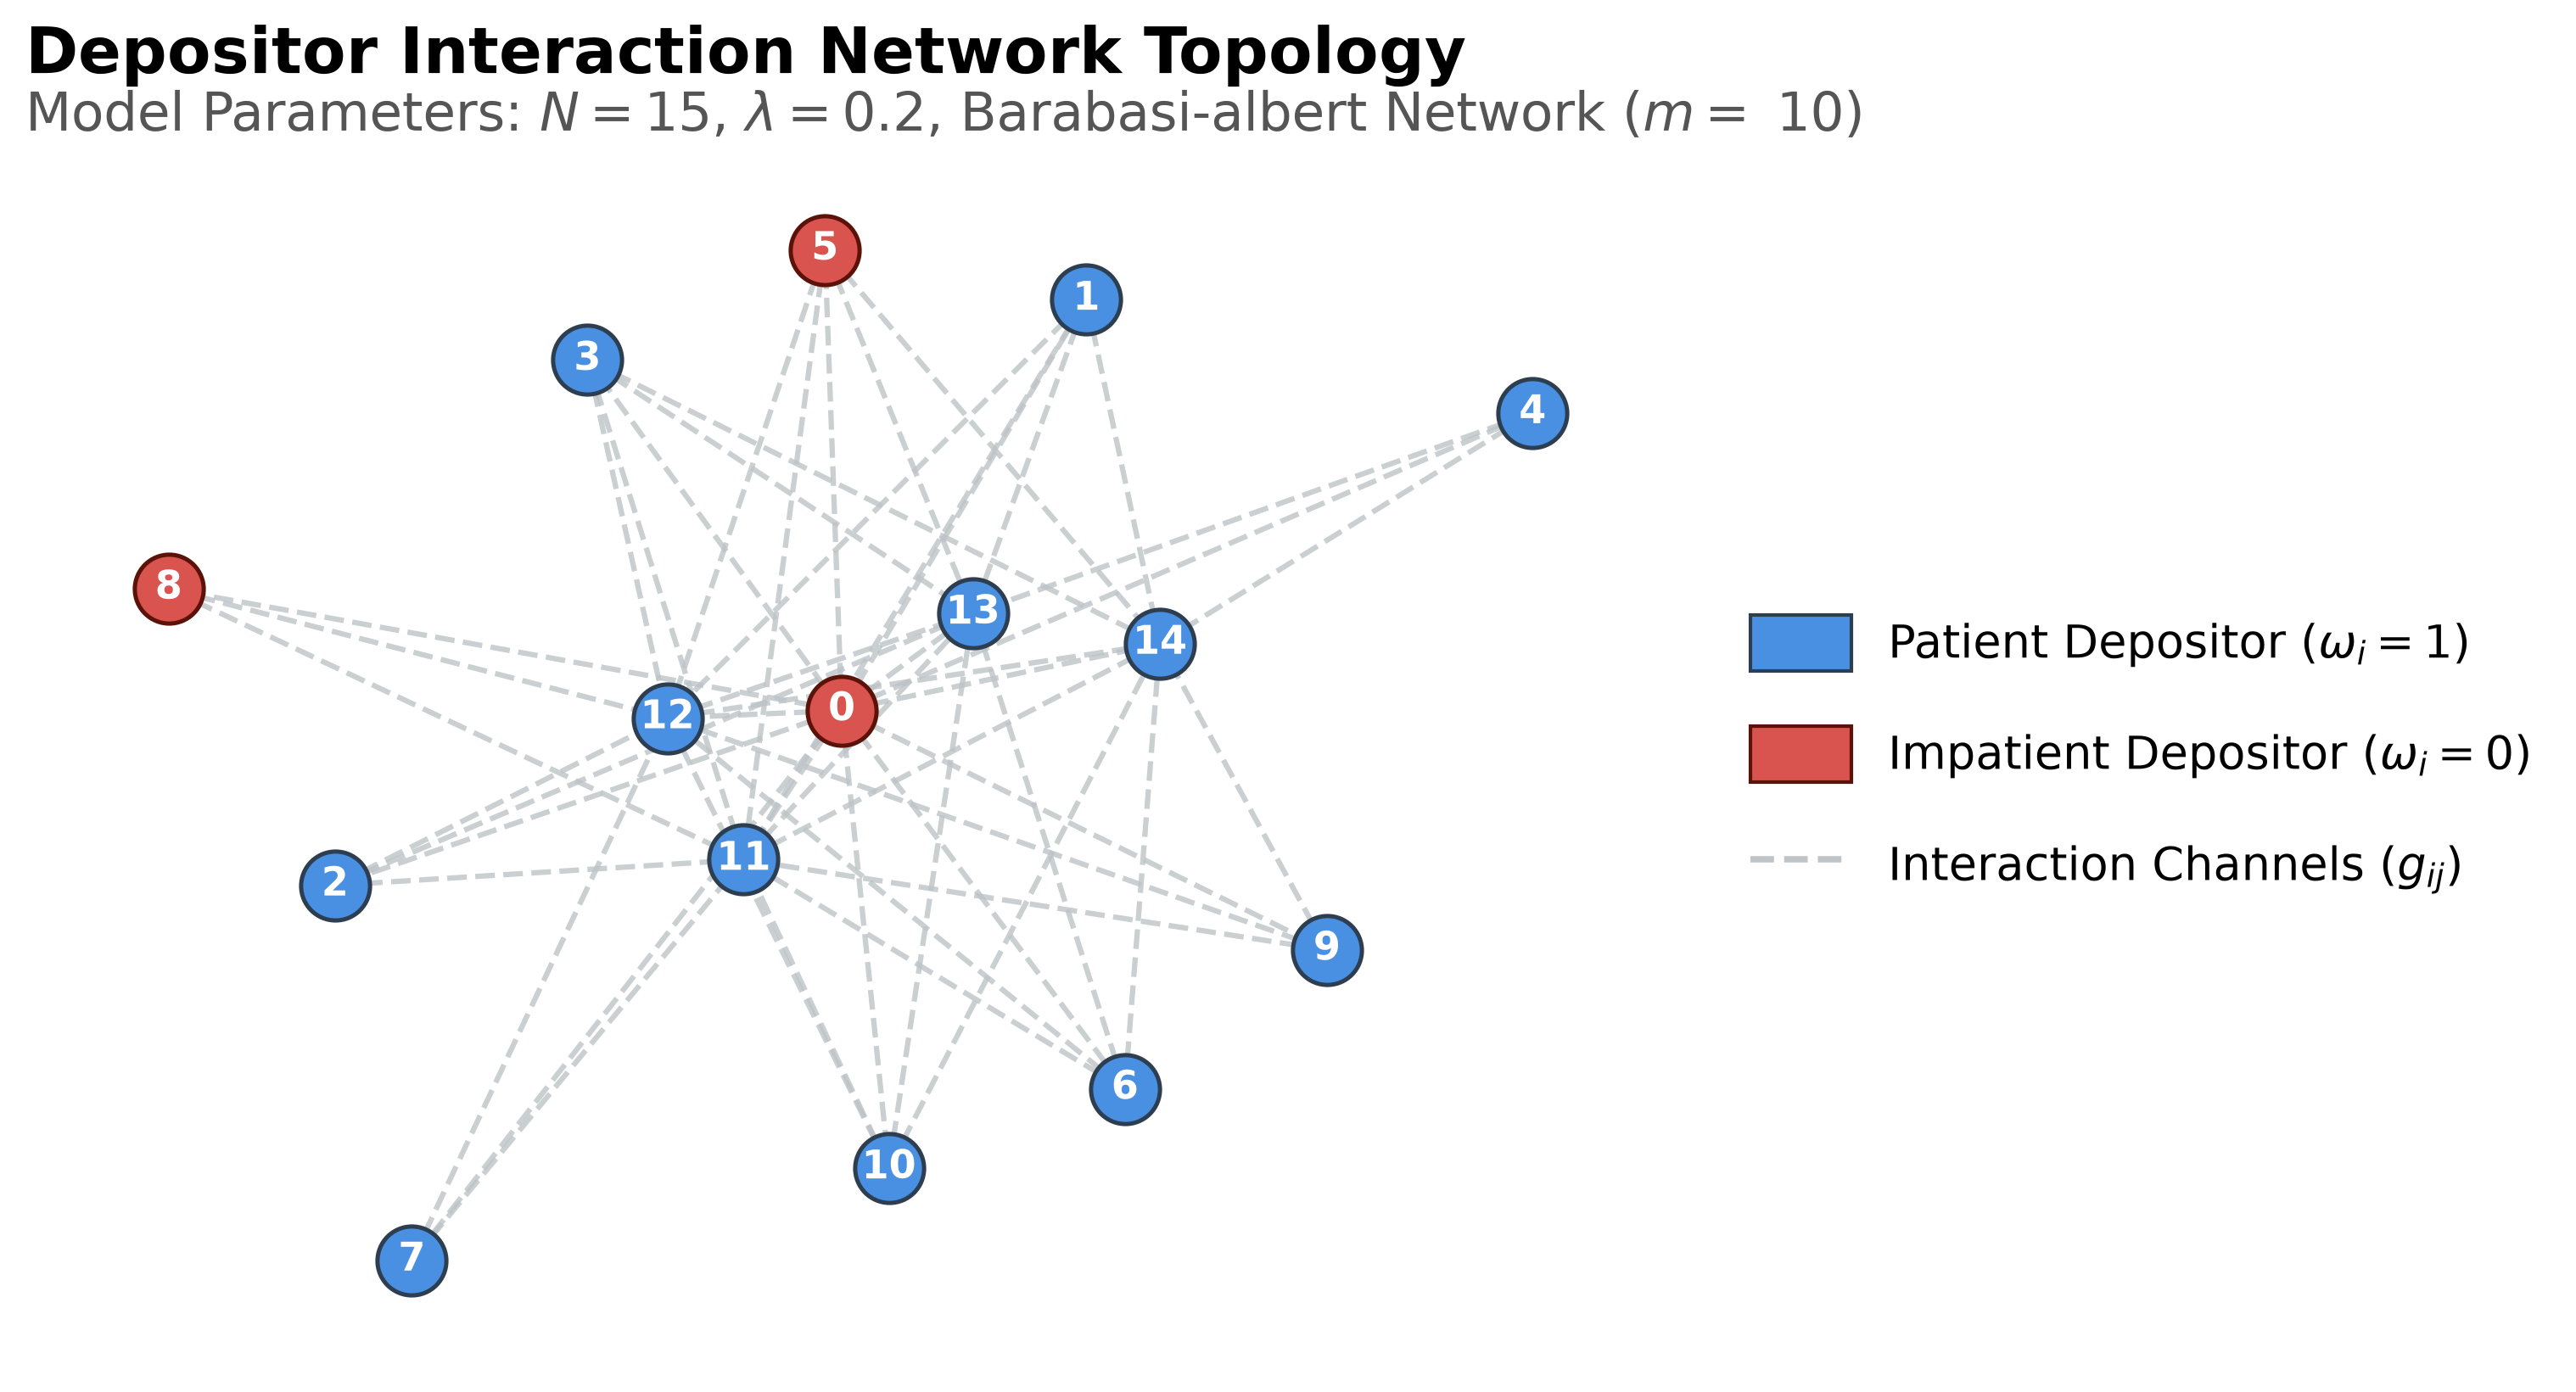

In [89]:
SIMU.graph()

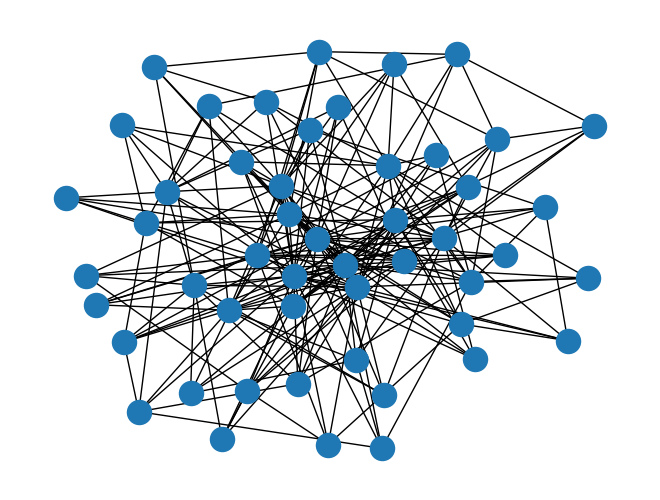

In [61]:
G3 = nx.barabasi_albert_graph(n=50, m=5, seed=42)
nx.draw(G3)